In [27]:
import collections
import inspect
import time
import numpy as np
import torch
from torch import nn
import inspect

from matplotlib import pyplot as plt
from matplotlib_inline import backend_inline

from IPython import display

In [28]:
def add_to_class(Class):
    def wrapper(obj):
        setattr(Class, obj.__name__, obj)
    return wrapper

class A:
    def __init__(self):
        self.b = 1
a=A()

@add_to_class(A)
def do(self):
    print(self.b)

a.do()

1


In [29]:
class HyperParameters:
    def save_hyperparameters(self, ignore=[]):
        frame = inspect.currentframe().f_back
        _,_,_,local_vars=inspect.getargvalues(frame)
        self.hparams={k:v for k,v in local_vars.items()
                      if k not in set(ignore+['self']) and not k.startswith('_')}
        for k,v in self.hparams.items():
            setattr(self,k,v)


class B(HyperParameters):
     def __init__(self, a, b, c):
         self.save_hyperparameters(ignore=['c'])
         print(self.a, self.b)
         print(hasattr(self,'c'))

b = B(a=1,b=2,c=3)

1 2
False


In [30]:
def use_svg_display():
    backend_inline.set_matplotlib_formats('svg')

class ProgressBoard(HyperParameters):
    def __init__(self, xlabel=None, ylabel=None, xlim=None, ylim=None, xscale='linear', yscale='linear',
                 ls=['-', '--', '-.', ':'], colors=['C0', 'C1', 'C2', 'C3'], fig=None, axes=None, figsize=(3.5,2.5),
                 display=True):
        self.save_hyperparameters()

    def draw(self, x, y, label, every_n=1):
        Point = collections.namedtuple('Point', ['x', 'y'])
        if not hasattr(self, 'raw_points'):
            self.raw_points = collections.OrderedDict()
            self.data = collections.OrderedDict()
        if label not in self.raw_points:
            self.raw_points[label] = []
            self.data[label] = []
        points = self.raw_points[label]
        line = self.data[label]
        points.append(Point(x, y))
        if len(points) != every_n:
            return

        mean = lambda x: sum(x)/len(x)
        line.append(Point(mean([p.x for p in points]), mean([p.y for p in points])))
        points.clear()

        if not self.display:
            return
        use_svg_display()
        if self.fig is None:
            self.fig = plt.figure(figsize=self.figsize)
        plt_lines, labels = [], []
        for (k,v), ls, color in zip(self.data.items(), self.ls, self.colors):
            plt_lines.append(plt.plot([p.x for p in v], [p.y for p in v], linestyle=ls, color=color)[0])
            labels.append(k)

        axes=self.axes if self.axes else plt.gca()
        if self.xlim: axes.set_xlim(self.xlim)
        if self.ylim: axes.set_ylim(self.ylim)
        if not self.xlabel: self.xlabel='x'
        axes.set_xlabel(self.xlabel)
        axes.set_ylabel(self.ylabel)
        axes.set_xscale(self.xscale)
        axes.set_yscale(self.yscale)
        axes.legend(plt_lines, labels)
        display.display(self.fig)
        display.clear_output(wait=True)


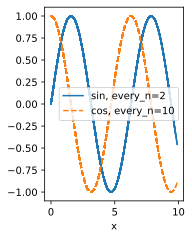

In [31]:
board = ProgressBoard('x')
for x in np.arange(0,10,0.1):
    board.draw(x, np.sin(x), 'sin, every_n=2')
    board.draw(x, np.cos(x), 'cos, every_n=10')